# 00 — Analyse exploratoire, détection des doublons et découpage anti-fuite

**Projet DiagnoCulture — Partie 1.1 de l'énoncé.**

Ce notebook produit le **découpage unique** (`results/00_split/train.csv`, `val.csv`, `test.csv`) que tous les autres notebooks réutilisent. C'est la fondation de la rigueur expérimentale du projet :

1. inventaire des images et effectifs par classe (déséquilibre) ;
2. détection des **quasi-doublons** (même feuille sous plusieurs formes) par *perceptual hashing* ;
3. découpage **70 / 15 / 15 stratifié par groupe** (seed 42) et vérification qu'aucune feuille n'est partagée ;
4. statistiques de normalisation calculées **sur l'apprentissage uniquement**.


In [ ]:
# === Configuration (Colab, Kaggle ou local) ===
ALLOW_CPU = True   # True seulement pour les notebooks sans entraînement (00 et 06)
REPO_URL = "https://github.com/fayelise/diagnoculture.git"   # utilisé sur Kaggle uniquement

import os, sys, subprocess
from pathlib import Path

# 1. Environnement. Colab est testé AVANT Kaggle : sur Colab, kagglehub peut créer /kaggle/input.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
IN_KAGGLE = not IN_COLAB and "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB:
    # Projet sur Google Drive : résultats et checkpoints survivent aux déconnexions
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/diagnoculture")
    os.environ["DIAGNO_CACHE"] = "/content/cache"   # cache d'images sur le disque local de Colab (rapide)
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):   # jeton Kaggle (Secrets Colab)
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
elif IN_KAGGLE:
    # Code cloné depuis GitHub ; résultats du notebook précédent (ajouté en Input) recopiés
    # dans /kaggle/working : l'Output de ce notebook contiendra donc toute la chaîne.
    import shutil
    ROOT = Path("/kaggle/working/diagnoculture")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    for inp in Path("/kaggle/input").iterdir():
        for prev in (inp / "results", inp / "diagnoculture" / "results"):
            if (prev / "00_split").is_dir():
                shutil.copytree(prev, ROOT / "results", dirs_exist_ok=True)
else:
    # Local : notebook lancé depuis notebooks/ ou depuis la racine du dépôt
    ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

assert (ROOT / "src" / "utils.py").exists(), f"Projet introuvable dans {ROOT} (voir README, section Installation)"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# 2. Paquets absents des images Colab / Kaggle (en local : pip install -r requirements.txt)
if IN_COLAB or IN_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo==1.8.0", "ImageHash==4.3.2",
                    "grad-cam==1.5.7", "onnx==1.23.2", "onnxruntime==1.29.0",
                    "umap-learn==0.5.12", "kagglehub==1.0.2"], check=True)

# 3. Configuration du projet
from src.utils import load_config, resolve_paths, set_seed, ensure_data, get_device, machine_info, TestGuard
cfg = load_config()
set_seed(cfg["seed"])
paths = resolve_paths(cfg)
DATA_ROOT = ensure_data(cfg)          # télécharge PlantVillage au 1er lancement de la session (hors Kaggle)
DEVICE = get_device()
guard = TestGuard(paths["results"])   # le test ne sert qu'une fois par modèle final
FORCE_TEST_RERUN = False              # True uniquement pour ré-exécuter à l'identique après une coupure
print("Projet :", ROOT, "| données :", DATA_ROOT, "| device :", DEVICE)
print(machine_info())

# 4. Garde-fou GPU : sur CPU, chaque epoch est 40 à 80 fois plus lente et le budget train.max_minutes
#    coupe les entraînements après 1 à 4 epochs (cause des résultats invalides de la 1re exécution).
#    DIAGNO_ALLOW_CPU=1 sert uniquement au test rapide du pipeline (README).
if DEVICE.type != "cuda" and not (ALLOW_CPU or os.environ.get("DIAGNO_ALLOW_CPU") == "1"):
    raise RuntimeError("Pas de GPU : Exécution → Modifier le type d'exécution → T4 GPU "
                       "(Kaggle : Session options → Accelerator → GPU T4).")

In [2]:
import json
import time
from importlib.metadata import version, PackageNotFoundError

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.datasets import (CLASSES, HEALTHY, scan_dataset, scan_other_species, load_image, compute_hashes,
                          group_near_duplicates, group_stratified_split, check_no_leakage, compute_norm_stats,
                          popcount64, _phash_bits, IMAGENET_MEAN, IMAGENET_STD)
from src.utils import save_json

OUT = paths["split_dir"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

# Versions réellement utilisées (reproductibilité)
pkgs = ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "imagehash", "grad-cam", "onnxruntime"]
env_versions = {}
for p in pkgs:
    try:
        env_versions[p] = version(p)
    except PackageNotFoundError:
        env_versions[p] = None
env_versions.update(machine_info())
save_json(env_versions, paths["results"] / "env_versions.json")
env_versions

{'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'numpy': '2.1.3',
 'pandas': '2.2.3',
 'scikit-learn': '1.6.1',
 'imagehash': '4.3.2',
 'grad-cam': '1.5.7',
 'onnxruntime': '1.29.0',
 'env': 'colab',
 'python': '3.13.15',
 'cpu': 'x86_64',
 'cpu_count': 2,
 'gpu': 'Tesla T4'}

## 1. Inventaire et effectifs par classe

Les noms de dossiers varient selon la version de PlantVillage (`Tomato___Early_blight`, `Tomato_Early_blight`…) : `scan_dataset` les ramène à 10 noms canoniques. Dans la version *abdallahalidev/plantvillage-dataset*, chaque image existe en `color`, `grayscale` et `segmented` : **seule la variante `color` est conservée** (sinon chaque feuille compterait trois fois  ce qui serait une première source de fuite).

Version utilisée : /kaggle/input/plantvillage-dataset/plantvillage dataset/color
Nombre total d'images tomate : 18160
Rapport de déséquilibre (max/min) : 14.4


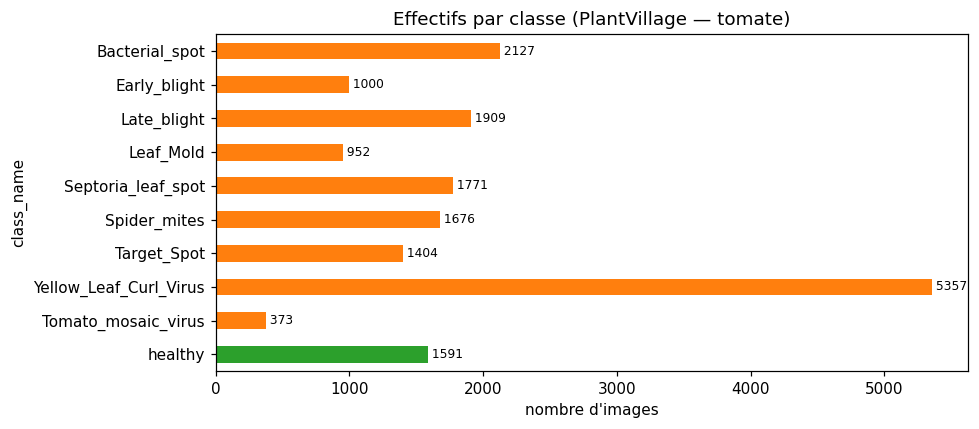

In [3]:
df = scan_dataset(DATA_ROOT, cfg)
counts = df["class_name"].value_counts().reindex(CLASSES)
print(f"Version utilisée : {DATA_ROOT}\nNombre total d'images tomate : {len(df)}")
print(f"Rapport de déséquilibre (max/min) : {counts.max() / counts.min():.1f}")

fig, ax = plt.subplots(figsize=(9, 4))
counts.plot.barh(ax=ax, color=["tab:green" if c == HEALTHY else "tab:orange" for c in counts.index])
for i, v in enumerate(counts.values):
    ax.text(v, i, f" {v}", va="center", fontsize=8)
ax.set(xlabel="nombre d'images", title="Effectifs par classe (PlantVillage — tomate)")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(OUT / "class_counts.png", dpi=150)

Les classes sont déséquilibrées (par exemple *Yellow_Leaf_Curl_Virus* est bien plus fréquente que *Tomato_mosaic_virus*). Conséquences :
- l'accuracy seule est trompeuse (un modèle qui ignore les petites classes peut avoir une bonne accuracy) → on rapporte le **F1 macro** et le **rappel par classe** ;
- le découpage doit être **stratifié** pour que chaque ensemble ait les mêmes proportions.

## 2. Exemples d'images

On observe le **fond uniforme de laboratoire** : c'est le risque de *shortcut learning*  (le modèle pourrait apprendre l'éclairage ou le fond propre à une session de prise de vue plutôt que la lésion).

In [4]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(9, 2 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    sample = df[df["class_name"] == c].sample(5, random_state=cfg["seed"])
    for k, rel in enumerate(sample["relpath"]):
        axes[r, k].imshow(load_image(DATA_ROOT / rel))
        axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "examples.png", dpi=120)

sizes = pd.Series([Image.open(DATA_ROOT / r).size for r in df["relpath"].sample(300, random_state=0)]).value_counts()
print("Tailles d'image observées (échantillon de 300) :\n", sizes)

Output hidden; open in https://colab.research.google.com to view.

## 3. Détection des quasi-doublons (anti-fuite)

**Problème.** Certaines versions de PlantVillage contiennent des variantes augmentées (rotations, symétries, recadrages) d'une même feuille. Si une variante est en apprentissage et une autre en test, le modèle est évalué sur une feuille qu'il a déjà vue : la performance est surestimée (*data leakage*).

**Méthode.**
1. **pHash** (*perceptual hash*) : image réduite en 32×32 niveaux de gris → DCT 2D → on garde les 8×8 coefficients de basse fréquence → bit = 1 si le coefficient dépasse la médiane. Deux images visuellement proches ont des hash proches au sens de la **distance de Hamming** (nombre de bits différents sur 64). Contrairement au MD5 (doublons exacts uniquement), le pHash résiste à la compression JPEG, aux petits changements de luminosité et au redimensionnement.
2. Le pHash **n'est pas invariant** aux rotations : on calcule donc le hash des **8 transformations** du groupe diédral (rotations 0/90/180/270°, avec et sans symétrie) et on prend la distance minimale.
3. Les noms de fichiers PlantVillage contiennent un **UUID de feuille** : deux fichiers de même UUID sont regroupés.
4. Les paires liées sont fusionnées en **groupes** (union-find) : un groupe = une feuille.

On vérifie d'abord que notre implémentation vectorisée donne exactement le même hash que la bibliothèque `imagehash`.

In [5]:
import imagehash

for rel in df["relpath"].sample(20, random_state=1):
    ref = imagehash.phash(Image.open(DATA_ROOT / rel), hash_size=cfg["dedup"]["hash_size"]).hash.flatten()
    g = np.asarray(Image.open(DATA_ROOT / rel).convert("L").resize((32, 32), Image.LANCZOS), dtype=np.float64)
    assert (ref == _phash_bits(g, cfg["dedup"]["hash_size"])).all()
print("Implémentation pHash identique à imagehash.phash")

Implémentation pHash identique à imagehash.phash


In [6]:
t0 = time.time()
md5, H = compute_hashes(df, DATA_ROOT, cfg["dedup"]["hash_size"], cfg["dedup"]["dihedral"])
df["md5"] = md5
print(f"Hash calculés pour {len(df)} images en {time.time() - t0:.0f} s")

# Doublons EXACTS (même fichier, octet pour octet)
dup_exact = df[df.duplicated("md5", keep=False)]
conflicts = dup_exact.groupby("md5")["class_name"].nunique()
conflict_md5 = conflicts[conflicts > 1].index
print(f"Fichiers impliqués dans des doublons exacts : {len(dup_exact)}")
print(f"Doublons exacts avec des étiquettes CONTRADICTOIRES (retirés) : {df['md5'].isin(conflict_md5).sum()}")
keep = ~df["md5"].isin(conflict_md5)
df, H = df[keep].reset_index(drop=True), H[keep.to_numpy()]

Hash calculés pour 18160 images en 59 s
Fichiers impliqués dans des doublons exacts : 28
Doublons exacts avec des étiquettes CONTRADICTOIRES (retirés) : 0


# Calibration du seuil de Hamming

## On calcule pour chaque image la distance à son **plus proche voisin** (même classe, 8 transformations). Si le jeu contient des variantes d'une même feuille, on voit un pic près de 0, bien séparé de la masse des feuilles différentes. Le seuil (`dedup.hamming_threshold` dans le config, 6 par défaut) doit se placer **dans le creux** entre les deux modes. On l'appuie aussi visuellement sur des paires d'images à différentes distances.

Regroupement en 14 s
count    18160.000000
mean        11.552753
std          2.470905
min          0.000000
25%         10.000000
50%         12.000000
75%         14.000000
max         20.000000
dtype: float64


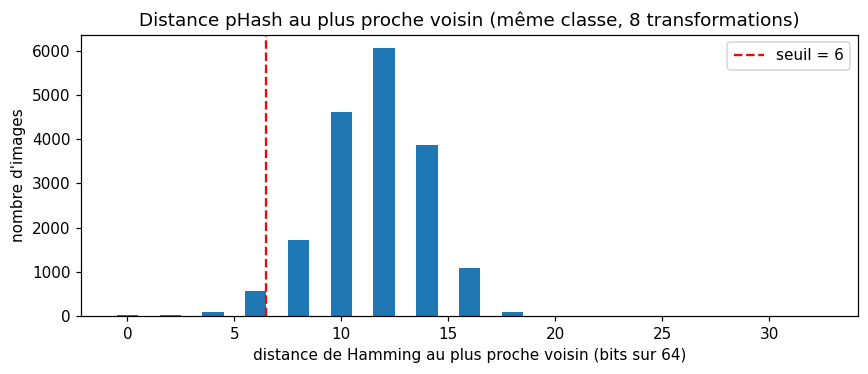

In [7]:
thr = cfg["dedup"]["hamming_threshold"]
t0 = time.time()
groups, nn_dist = group_near_duplicates(df, H, thr)
df["group"] = groups
df["nn_dist"] = nn_dist
print(f"Regroupement en {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(nn_dist, bins=np.arange(0, 34) - 0.5, color="tab:blue")
ax.axvline(thr + 0.5, color="red", ls="--", label=f"seuil = {thr}")
ax.set(xlabel="distance de Hamming au plus proche voisin (bits sur 64)", ylabel="nombre d'images",
       title="Distance pHash au plus proche voisin (même classe, 8 transformations)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "dedup_nn_distance.png", dpi=150)
print(pd.Series(nn_dist).describe())

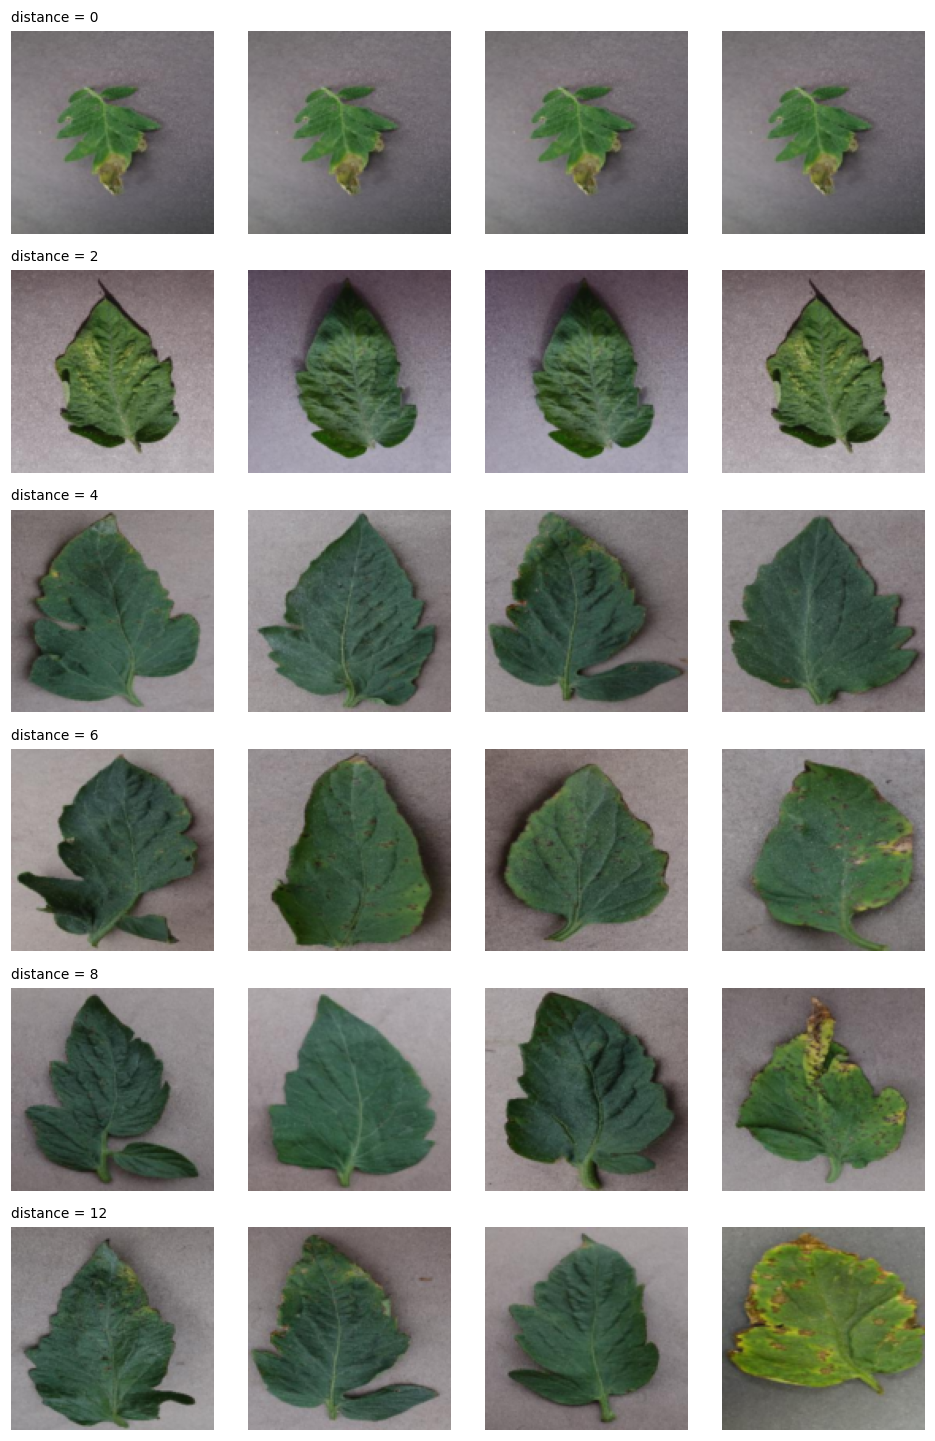

In [8]:
# Paires d'exemples à différentes distances : où passe la frontière « même feuille » ?
def show_pairs(dists=(0, 2, 4, 6, 8, 12), per=2):
    dists = [d for d in dists if (df["nn_dist"] == d).any()]   # seulement les distances observées
    fig, axes = plt.subplots(len(dists), 2 * per, figsize=(2.2 * 2 * per, 2.2 * len(dists)))
    axes = np.atleast_2d(axes)
    for r, d in enumerate(dists):
        cand = df[df["nn_dist"] == d].head(per)
        for k, (i, row) in enumerate(cand.iterrows()):
            same = df[(df["class_name"] == row["class_name"]) & (df.index != i)].index.to_numpy()
            j = same[popcount64(H[i, 0] ^ H[same]).min(axis=1).argmin()]
            for m, idx in enumerate((i, j)):
                axes[r, 2 * k + m].imshow(load_image(DATA_ROOT / df.loc[idx, "relpath"], 128))
        for a in axes[r]:
            a.axis("off")
        axes[r, 0].set_title(f"distance = {d}", loc="left", fontsize=9)
    fig.tight_layout()
    fig.savefig(OUT / "dedup_pairs.png", dpi=120)

show_pairs()

In [9]:
gsize = df.groupby("group").size()
dedup_report = {
    "n_images": int(len(df)), "n_groups": int(len(gsize)), "hamming_threshold": thr,
    "images_in_multi_image_groups": int(gsize[gsize > 1].sum()), "largest_group": int(gsize.max()),
    "group_size_distribution": {int(k): int(v) for k, v in gsize.value_counts().sort_index().items()},
}
print(json.dumps(dedup_report, indent=2))
# Garde-fou : un seuil trop élevé crée des « chaînes » (A~B, B~C...) qui fusionnent des feuilles différentes
if gsize.max() > 0.01 * len(df):
    print("Groupe anormalement grand : seuil probablement trop élevé (fusion de feuilles distinctes).")
save_json(dedup_report, OUT / "dedup_report.json")

{
  "n_images": 18160,
  "n_groups": 17689,
  "hamming_threshold": 6,
  "images_in_multi_image_groups": 818,
  "largest_group": 25,
  "group_size_distribution": {
    "1": 17342,
    "2": 289,
    "3": 40,
    "4": 5,
    "5": 5,
    "6": 4,
    "7": 1,
    "8": 1,
    "11": 1,
    "25": 1
  }
}


## 4. Découpage 70 / 15 / 15 stratifié **par groupe**

Pour chaque classe, on mélange les **groupes** (graine 42) et on les attribue entiers à train, val ou test jusqu'à atteindre 70 / 15 / 15 % des images de la classe. Deux propriétés :
- **stratification** : chaque classe a ~70/15/15 % de ses images dans chaque ensemble ;
- **pas de fuite** : un groupe (une feuille) n'apparaît que dans un ensemble.

Rappel du protocole : *train* sert à apprendre, *val* à choisir hyperparamètres, epochs et **tous les seuils**, *test* n'est utilisé **qu'une fois par modèle final**.

In [10]:
df = group_stratified_split(df, (cfg["split"]["train"], cfg["split"]["val"], cfg["split"]["test"]), seed=cfg["seed"])
check_no_leakage(df)

table = pd.crosstab(df["class_name"], df["split"]).reindex(CLASSES)[["train", "val", "test"]]
table["total"] = table.sum(axis=1)
props = table[["train", "val", "test"]].div(table["total"], axis=0).round(3)
display(table.join(props, rsuffix=" (%)"))
table.to_csv(OUT / "split_counts.csv")

cols = ["relpath", "class_name", "label", "group", "md5", "split"]
for s in ("train", "val", "test"):
    df.loc[df["split"] == s, cols].to_csv(OUT / f"{s}.csv", index=False)
save_json({"classes": CLASSES, "healthy": HEALTHY}, OUT / "classes.json")
print("Fichiers écrits :", sorted(p.name for p in OUT.glob("*.csv")))

OK : aucun groupe ni fichier identique partagé entre train / val / test.


split,train,val,test,total,train (%),val (%),test (%)
class_name,,,,,,,
Bacterial_spot,1489,319,319,2127,0.7,0.15,0.15
Early_blight,700,150,150,1000,0.7,0.15,0.15
Late_blight,1336,287,286,1909,0.7,0.15,0.15
Leaf_Mold,666,143,143,952,0.7,0.15,0.15
Septoria_leaf_spot,1240,265,266,1771,0.7,0.15,0.15
Spider_mites,1173,251,252,1676,0.7,0.15,0.15
Target_Spot,983,210,211,1404,0.7,0.15,0.15
Yellow_Leaf_Curl_Virus,3750,803,804,5357,0.7,0.15,0.15
Tomato_mosaic_virus,261,56,56,373,0.7,0.15,0.15


Fichiers écrits : ['ood_plantvillage.csv', 'split_counts.csv', 'test.csv', 'train.csv', 'val.csv']


## 5. Statistiques de normalisation (train uniquement)

On standardise chaque canal : `x' = (x − moyenne) / écart-type`. Des entrées centrées-réduites accélèrent et stabilisent la descente de gradient . Les statistiques sont calculées **sur l'apprentissage uniquement** : les calculer sur val/test ferait passer de l'information de ces ensembles dans le modèle.

Choix par famille de modèles :

| Modèles                                 | Normalisation                                | Pourquoi                                                                                                                  |
|:----------------------------------------|:---------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------|
| CNN entraînés de zéro (nb 01)           | moyenne/écart-type **du train PlantVillage** | le réseau apprend tout à partir de nos données                                                                            |
| Backbones pré-entraînés (nb 02, 04, 06) | moyenne/écart-type **ImageNet**              | les filtres ont été appris sur des entrées normalisées ainsi ; changer la normalisation décalerait toutes les activations |
| Auto-encodeurs / VAE (nb 03-05)         | aucune, pixels dans [0, 1]                   | la sortie Sigmoid reconstruit directement l'image ; l'erreur MSE reste interprétable                                      |

In [11]:
norm = compute_norm_stats(df[df["split"] == "train"], DATA_ROOT, cfg["resolution"]["scratch"], seed=cfg["seed"])
save_json(norm, OUT / "norm_stats.json")
print("Train PlantVillage : moyenne", np.round(norm["mean"], 3), "écart-type", np.round(norm["std"], 3))
print("ImageNet           : moyenne", IMAGENET_MEAN, "écart-type", IMAGENET_STD)

Train PlantVillage : moyenne [0.451 0.466 0.401] écart-type [0.175 0.152 0.191]
ImageNet           : moyenne (0.485, 0.456, 0.406) écart-type (0.229, 0.224, 0.225)


## 6. Préparation du jeu hors-distribution (Partie 4)

- **Autres espèces PlantVillage** : si le jeu téléchargé les contient (pomme, poivron, pomme de terre…), on en tire un échantillon reproductible.
- **Photos personnelles** : au moins 30 photos prises par vos soins (mains, sol, autres plantes, feuilles de tomate sur fond non uniforme) à déposer dans `data/ood/custom/` (non versionné).

In [12]:
ood_pv = scan_other_species(DATA_ROOT, cfg, cfg["part4"]["ood_other_species_max"])
ood_pv.to_csv(OUT / "ood_plantvillage.csv", index=False)
print(f"Autres espèces PlantVillage : {len(ood_pv)} images, {ood_pv['class_name'].nunique()} classes")
from src.ood import list_images
n_custom = len(list_images(paths["ood_custom"]))
print(f"Photos personnelles dans {paths['ood_custom']} : {n_custom}" + ("" if n_custom >= 30 else "  l'énoncé en exige au moins 30"))

Autres espèces PlantVillage : 300 images, 28 classes
Photos personnelles dans /content/drive/MyDrive/diagnoculture/data/ood/custom : 0  l'énoncé en exige au moins 30
